# Body fat: linear or smooth effects

Body measurements provide a less expensive way to estimate body fat than a
dual-energy X-ray absorptiometry (DEXA) scan. We will fit a model that predicts DEXA fat from those measurements,
choose how long to boost, and examine whether smooth effects improve on
straight lines.

This case introduces `gamboost`, `cvrisk`, partial-effect plots and prediction
on a new frame. You need basic regression knowledge; the boosting arguments
are explained as they appear. The main analysis ends with a prediction table.
The extensions examine curvature and its stability across resamples.

:::{admonition} What this study estimates
:class: dropdown

| | |
|---|---|
| **Target** | predicting DEXA fat and comparing straight and smooth effects |
| **Observed response** | `DEXfat`, body fat measured by DEXA |
| **Estimand** | mean DEXA fat conditional on the offered measurements, and the descriptive difference in tuned cross-validation error |
| **Units** | fat and effects in kg; squared error in kg²; age in years and circumference or breadth in cm |
| **Sampling unit** | one woman |
| **Dependence** | women treated as independent; their predictors are correlated |
| **Split / resampling unit** | the woman, for ten-fold cross-validation and bootstrap resampling |
| **Tuning** | `mstop` on the shared ten-fold scheme; bootstrap bands repeat stopping selection on inner bootstrap folds |
| **Uncertainty** | descriptive paired fold differences, pointwise bootstrap effect intervals, and selection frequencies at fixed `mstop` |
| **Claim type** | exploratory predictive comparison and descriptive effects; no causal interpretation |
:::

## The data

The `bodyfat` data contain 71 women from the study used in the mboost tutorial
{cite:p}`hofner2014mboost_tutorial`. The response, `DEXfat`, is body fat in kg.
The nine predictors are age in years, four circumference or breadth
measurements in cm, and four derived anthropometric indices. A row describes
one woman, and we treat the women as independent observations.

We load a Polars frame and inspect a few measurements before fitting.

In [1]:
import altair as alt
import numpy as np
import polars as pl
from IPython.display import display

import mboostrs as mb

data = mb.datasets.bodyfat(output="polars")
predictors = [name for name in data.columns if name != "DEXfat"]
n = data.height
display(data.select("DEXfat", "age", "waistcirc", "hipcirc").head())

DEXfat,age,waistcirc,hipcirc
f64,i64,f64,f64
41.68,57,100.0,112.0
43.29,65,99.5,116.5
35.41,59,96.0,108.5
22.79,58,72.0,96.5
36.42,60,89.5,100.5


The first column is what the model will predict. Waist and hip circumference
can carry overlapping information, so an effect will describe a measurement's
contribution conditional on the other terms offered to the model.

## A linear model: `gamboost`

`gamboost` fits an additive predictor: a constant plus contributions from the
terms in the formula. `bols(hipcirc)`, for example, offers a straight-line
contribution for hip circumference. At each boosting step, the algorithm
chooses one term and adds a small part of its fitted update.

`mstop=600` is the maximum number of updates we make available. `nu=0.1` adds
one tenth of the chosen update at each step. We will select an earlier stopping
point using cross-validation. `Gaussian()` uses squared-error loss, so the
prediction estimates mean DEXA fat in kg.

In [2]:
linear_formula = (
    "DEXfat ~ bols(age) + bols(waistcirc) + bols(hipcirc) + "
    "bols(elbowbreadth) + bols(kneebreadth) + bols(anthro3a) + "
    "bols(anthro3b) + bols(anthro3c) + bols(anthro4)"
)
linear_path = mb.gamboost(
    linear_formula, data=data, family=mb.Gaussian(),
    control=mb.boost_control(mstop=600, nu=0.1),
)
print(f"Fitted a path of {linear_path.mstop} boosting updates.")

Fitted a path of 600 boosting updates.


The object retains the path of fitted models. More updates allow more of the
training variation into the fit; choosing the endpoint solely by training
error would favour an unnecessarily complex model.

## The stopping point: `cvrisk`

Ten-fold cross-validation divides the women into ten groups. Each refit trains
on nine groups and scores the remaining group at each stopping point.
`optimal_mstop` is the iteration with the smallest average held-out loss.
We save the folds so that the smooth model later faces exactly the same splits.

Selected 43 updates; ten-fold RMSE 3.60 kg.


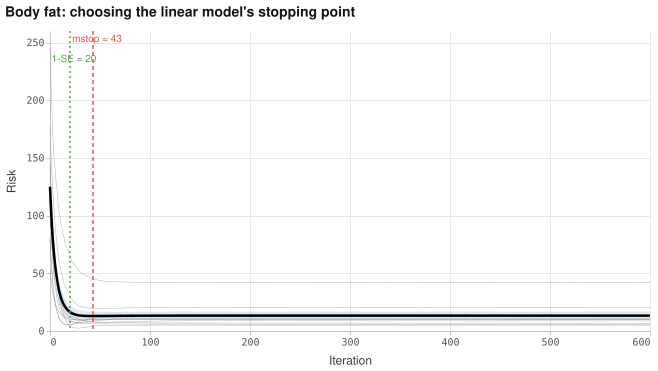

In [3]:
folds = mb.cv_weights(n, type="kfold", B=10, seed=1)
linear_cv = linear_path.cvrisk(folds=folds)
linear = linear_path[:linear_cv.optimal_mstop]
linear_mse = float(np.min(linear_cv.aggregate))
linear_rmse = float(np.sqrt(linear_mse))

print(f"Selected {linear_cv.optimal_mstop} updates; "
      f"ten-fold RMSE {linear_rmse:.2f} kg.")
mb.plot.plot_cvrisk(linear_cv).properties(title="Body fat: choosing the linear model's stopping point")

The curve selects {eval}`linear_cv.optimal_mstop` updates from the available
600. The vertical axis is mean squared error in kg²; its square root is
{eval}`f"{linear_rmse:.2f}"` kg, which expresses prediction error in the response's
units. The spread around the curve describes variation between folds.

`linear_path[:k]` returns the model after `k` updates. It does not select rows
of the data. Every prediction and effect below uses the truncated model.
If a curve reaches its minimum at the largest available iteration, extend the
path and repeat the tuning; `linear_cv.at_boundary()` checks that situation.

## A fitted effect

A partial effect is one term's contribution to the additive prediction. The
hip-circumference plot shows its contribution in kg against circumference in
cm. The line describes the fitted model. The scattered points are partial residuals: each woman's response with the contributions of the other terms removed, so each point is this term's contribution plus that woman's unexplained part.

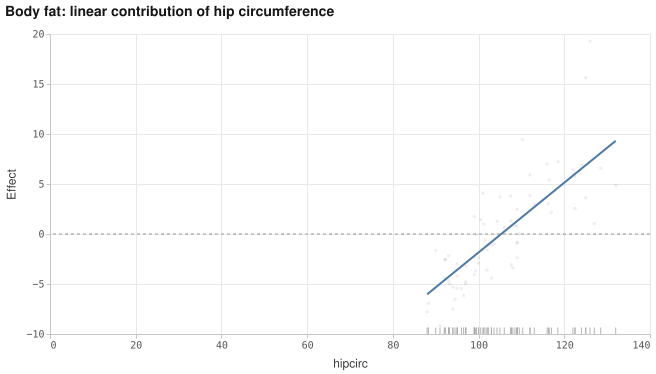

In [4]:
mb.plot.plot_partial_effects(linear, which="hipcirc").properties(
    title="Body fat: linear contribution of hip circumference",
)

The line is straight because we specified `bols`. Its vertical position is a
component of the full prediction: the offset (the constant the model starts from before its first update) and other measurements contribute
as well. A fitted slope describes an association among these women; changing
a woman's circumference is not an intervention evaluated by this study.

## Smooth effects: `bbs`

A smooth term can represent a slope that changes across the predictor's range.
`bbs(x, df=4)` uses a penalised spline, a curve built from local basis functions
with a penalty against excessive variation. Here `df=4` controls the flexibility
of each update; the number of boosting updates controls the accumulated fit.

We offer smooth terms for the same nine predictors and tune on the saved folds.
This compares two whole specifications. The default linear learner and the
four-degree-of-freedom spline have different flexibility per update.

In [5]:
smooth_formula = "DEXfat ~ " + " + ".join(
    f"bbs({name}, df=4)" for name in predictors
)
smooth_path = mb.gamboost(
    smooth_formula, data=data, family=mb.Gaussian(),
    control=mb.boost_control(mstop=600, nu=0.1),
)
smooth_cv = smooth_path.cvrisk(folds=folds)
smooth = smooth_path[:smooth_cv.optimal_mstop]
smooth_mse = float(np.min(smooth_cv.aggregate))

pl.DataFrame({
    "model": ["linear", "smooth"],
    "updates": [linear_cv.optimal_mstop, smooth_cv.optimal_mstop],
    "ten-fold MSE (kg²)": [linear_mse, smooth_mse],
    "ten-fold RMSE (kg)": [linear_rmse, np.sqrt(smooth_mse)],
})

model,updates,ten-fold MSE (kg²),ten-fold RMSE (kg)
str,i64,f64,f64
"""linear""",43,12.973904,3.601931
"""smooth""",43,11.21676,3.349143


The smooth model's ten-fold MSE is {eval}`f"{smooth_mse:.2f}"` kg², compared
with {eval}`f"{linear_mse:.2f}"` kg² for the linear model. To see how consistently
that difference appears, compare the models within each fold.

`compare_to` checks that the folds match and subtracts the second model's risk
from the first model's risk. Positive differences below favour the smooth model.

In [6]:
comparison = linear_cv.compare_to(smooth_cv)
print(comparison.describe())
pl.DataFrame({
    "fold": np.arange(1, comparison.n_folds + 1),
    "linear minus smooth MSE (kg²)": comparison.differences,
})

10 paired folds, mstop 43 vs 43
  mean risk difference: 1.75714 (favours the second)
  standard error: 1.49192 corrected, 1.02681 uncorrected
  No calibrated interval: the two models were compared at their own selected optima, so the interval would not cover the tuning bias. The comparison is descriptive.


fold,linear minus smooth MSE (kg²)
i64,f64
1,0.339194
2,-0.03079
3,-0.81699
4,-0.154867
5,1.035219
6,0.073038
7,3.275701
8,9.667929
9,4.429642


The average difference is {eval}`f"{comparison.mean_difference:.2f}"` kg²;
{eval}`int((comparison.differences > 0).sum())` of the
{eval}`comparison.n_folds` folds favour the smooth specification. Its advantage
varies substantially across these small held-out groups.

The report gives a corrected standard error of
{eval}`f"{comparison.se_corrected:.2f}"` kg² to describe the comparison's
variability. The correction is the Nadeau–Bengio adjustment: the folds share training rows, so the uncorrected standard error is too small, and the correction enlarges the variance of the mean difference by the ratio of held-out rows to training rows. It returns no confidence interval because both stopping points
were chosen on these same folds. The scores support an exploratory choice
between the specifications, not an independent estimate of the chosen model's
future accuracy or a test that individual effects are curved.

We can now inspect the smooth version of the same effect.

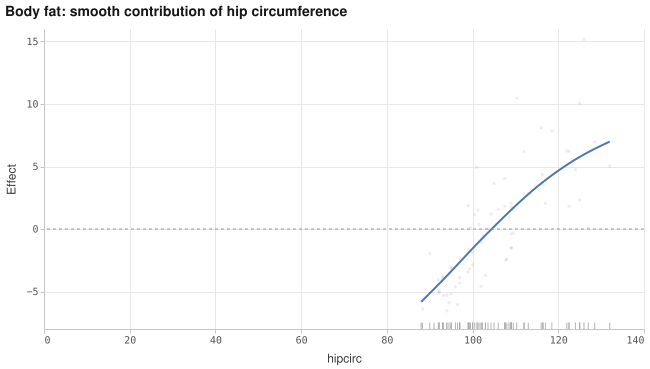

In [7]:
mb.plot.plot_partial_effects(smooth, which="hipcirc").properties(
    title="Body fat: smooth contribution of hip circumference",
)

The spline allows curvature, but a bend in one fitted curve is insufficient
evidence that the underlying effect is nonlinear. The extensions below
separate a linear component from a deviation and examine resampling variation.

## Predictions: `predict`

`predict(newdata=...)` combines all terms and the offset. The new frame must
contain the predictors used in the formula. We use the first three observed
measurement profiles to demonstrate the call, so this table illustrates the
output rather than providing another validation score.

In [8]:
profiles = data.select(predictors).head(3)
predictions = smooth.predict(newdata=profiles, type="response")
profiles.select("age", "waistcirc", "hipcirc").with_columns(
    pl.Series("predicted DEXA fat (kg)", predictions),
)

age,waistcirc,hipcirc,predicted DEXA fat (kg)
i64,f64,f64,f64
57,100.0,112.0,41.335062
65,99.5,116.5,43.557831
59,96.0,108.5,35.861413


Each row now has one predicted mean body-fat value in kg. The workflow is
reusable: fit a path, select its stopping point, inspect its terms, and predict
from a frame with the same measurements. The model's applicability remains
limited to populations and measurement ranges comparable to this small study.

The next sections are optional extensions. For more practice with stopping
rules, see [](stopping_rule.ipynb).


## Extension: linear and nonlinear components

The whole-model comparison does not identify which measurements need curves.
To examine that question, offer each measurement twice: as a linear learner and
as a learner representing departure from linearity.

`bbs(x, df=1, center=True)` removes the spline's constant and linear components
and penalises the remaining curve to one degree of freedom. This separates the
two kinds of contribution. The penalty construction is explained in
[](../methodology/base_learners.ipynb).

In [9]:
decomposed_formula = "DEXfat ~ " + " + ".join(
    f"bols({name}) + bbs({name}, df=1, center=True)" for name in predictors
)
decomposed_path = mb.gamboost(
    decomposed_formula, data=data, family=mb.Gaussian(),
    control=mb.boost_control(mstop=800, nu=0.1),
)
decomposed_cv = decomposed_path.cvrisk(folds=folds)
decomposed = decomposed_path[:decomposed_cv.optimal_mstop]

# One row per learner, including the ones that earned nothing: two
# learners share a column in this specification, and the per-learner
# table names them apart without a join.
updates = decomposed.selection_counts(output="polars")
learner_names = decomposed.base_learner_names()
curved_updates = updates.filter(pl.col("learner").str.ends_with("(bbs)"))
updates

learner,column,updates,share
str,str,i64,f64
"""kneebreadth (bbs)""","""kneebreadth""",24,0.242424
"""hipcirc (bbs)""","""hipcirc""",22,0.222222
"""anthro3b (bbs)""","""anthro3b""",17,0.171717
"""kneebreadth (bols)""","""kneebreadth""",10,0.10101
"""anthro3b (bols)""","""anthro3b""",8,0.080808
…,…,…,…
"""elbowbreadth (bbs)""","""elbowbreadth""",0,0.0
"""anthro3a (bbs)""","""anthro3a""",0,0.0
"""anthro3c (bbs)""","""anthro3c""",0,0.0


At {eval}`decomposed_cv.optimal_mstop` updates, the model has used
{eval}`curved_updates.height` deviation terms. The table distinguishes these
from the corresponding linear terms. Update counts describe this fit's path;
correlated measurements may substitute for each other across samples.

For hip circumference, `learner_index` selects the deviation term explicitly: it returns the position of a base learner in the fitted model, and when two learners share one column, `kind` (for example `"bbs"`) picks one by learner type.
Its plotted contribution is the part the linear learner cannot represent.

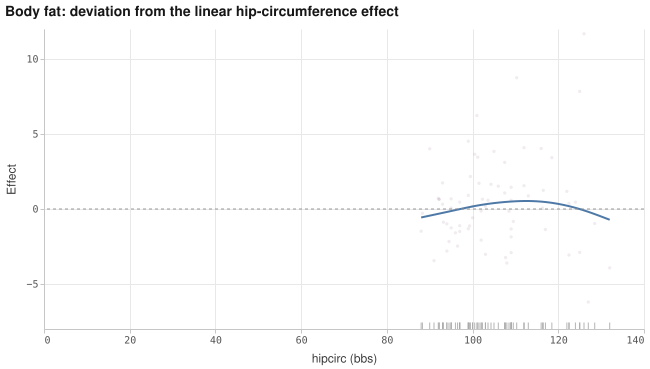

In [10]:
hip_deviation = decomposed.learner_index("hipcirc", kind="bbs")
mb.plot.plot_partial_effects(decomposed, which=hip_deviation).properties(
    title="Body fat: deviation from the linear hip-circumference effect",
)

## Extension: bootstrap effect intervals

A bootstrap repeatedly draws women with replacement and refits the model.
`confint` returns pointwise percentile intervals for the partial effects.
Here we bootstrap the smooth specification and repeat stopping selection within
each resample, using 25 inner bootstrap folds. Passing the full path keeps the
available stopping range at 600 updates.

We examine hip circumference only. These intervals describe refitting
variation for the specified model-building procedure. They are not prediction
intervals for individual women or a simultaneous test of linearity.

/tmp/ipykernel_67037/1442099172.py:1: UserWarning: Bootstrap intervals on a boosted fit under-cover (74% empirical coverage at nominal 90% on the book's additive benchmark): resampling reproduces the shrinkage that early stopping induces instead of correcting it. For calibrated bands, use confint(method='refit'), which refits the selected terms by REML (see mboostrs.selection.gam_refit).
  ci = smooth_path.confint(parm="hipcirc", B=300, B_mstop=25, seed=1)


/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamboost.py:3082: UserWarning: optimal mstop 599 is within 5% of the search cap 600; the search range was exhausted — consider increasing mstop and re-running cvrisk.
  result = CvRiskResult(


/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamboost.py:3082: UserWarning: optimal mstop 596 is within 5% of the search cap 600; the search range was exhausted — consider increasing mstop and re-running cvrisk.
  result = CvRiskResult(


Bootstrap refits used: 300/300; failed: 0; without retuning: 0.


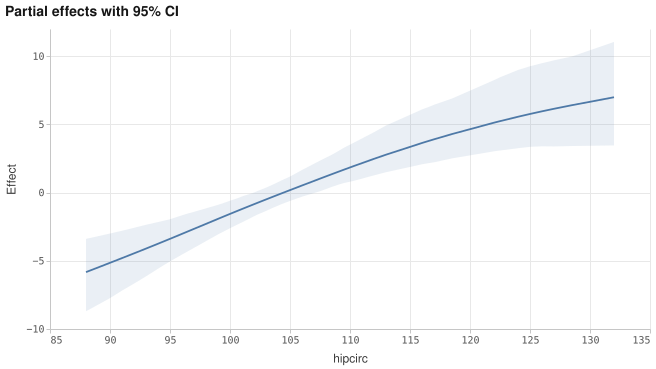

In [11]:
ci = smooth_path.confint(parm="hipcirc", B=300, B_mstop=25, seed=1)
print(f"Bootstrap refits used: {ci['n_used']}/{ci['B']}; "
      f"failed: {ci['n_failed']}; without retuning: {ci['n_untuned']}.")

# The plot takes the interval just computed: the replicate tally above
# belongs to the band below, and drawing it by bootstrapping the same
# 300 refits again would repeat the whole search for the same numbers.
mb.plot.plot_confint(smooth, parm="hipcirc", interval=ci)


The band should be read as uncertainty in the contribution, at each
circumference. It includes variation in which terms are selected and how long
they are boosted, within the stated search range. Assessing a departure from
linearity requires more than observing a bend in the central line.

## Extension: selection stability

We refit the decomposed model on 40 bootstrap samples and count how often each
deviation term receives any update. This experiment holds the stopping point
fixed at {eval}`decomposed_cv.optimal_mstop`, so it measures selection stability
conditional on that choice. It is distinct from the retuned effect intervals.

In [12]:
from collections import Counter

rng = np.random.default_rng(0)
replicates = 40
selected_counts = Counter()
for _ in range(replicates):
    rows = rng.integers(0, n, n)
    resample = data[rows]
    refit = mb.gamboost(
        decomposed_formula, data=resample, family=mb.Gaussian(),
        control=mb.boost_control(mstop=decomposed_cv.optimal_mstop, nu=0.1),
    )
    # Every deviation learner that earned at least one update on this
    # resample, by its disambiguated name.
    selected_counts.update(
        row["learner"] for row in refit.selection_counts(output="records")
        if row["updates"] > 0 and row["learner"].endswith("(bbs)"))

stability = pl.DataFrame([
    {"deviation term": name, "selected resamples": selected_counts[name],
     "fraction": selected_counts[name] / replicates}
    for name in learner_names if name.endswith("(bbs)")
]).sort("selected resamples", descending=True)
stability

deviation term,selected resamples,fraction
str,i64,f64
"""kneebreadth (bbs)""",33,0.825
"""anthro3b (bbs)""",30,0.75
"""hipcirc (bbs)""",25,0.625
"""age (bbs)""",18,0.45
"""elbowbreadth (bbs)""",16,0.4
"""anthro3c (bbs)""",15,0.375
"""anthro3a (bbs)""",14,0.35
"""waistcirc (bbs)""",8,0.2
"""anthro4 (bbs)""",2,0.05


The frequency table shows whether the single-fit choices recur. A fraction of
0.5 means that half the resampled data sets selected that deviation at least
once. This share describes selection in the resamples, and this
ordinary bootstrap does not provide the false-selection control of
[](../methodology/stability_selection.ipynb).

Shared-fold scores compare
whole specifications, partial effects describe the selected model, and
resampling shows how much its shape and selection change when the sample
changes.

```{bibliography}
:filter: docname in docnames
```